# TA-05: Klasifikasi Churn Pelanggan Telekomunikasi dengan Decision Tree

**Mata Praktikum:** Pembelajaran Mesin | **Modul 05:** Decision Tree
**Nama / NIM:** *[isi di sini]*

Notebook ini adalah lanjutan dari TP-05 dan memuat seluruh alur Tugas Akhir:

1. Memuat dataset dan eksplorasi data (EDA)
2. Pra-pemrosesan: nilai hilang dan fitur kategorikal
3. Model A (tanpa batasan, rawan overfit) dan Model B (di-pruning)
4. Evaluasi dan perbandingan kedua model
5. Visualisasi pohon, aturan jika-maka, dan feature importance (Model B)
6. Menyimpan model dengan Joblib untuk aplikasi Flask

**Dataset:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Letakkan file `WA_Fn-UseC_-Telco-Customer-Churn.csv` di folder `data/` (atau di folder yang sama dengan notebook ini). Jika memakai Google Colab, upload file CSV-nya ke sesi Colab.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


## 1. Memuat Dataset

In [2]:
CANDIDATES = ["data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
              "WA_Fn-UseC_-Telco-Customer-Churn.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("File CSV tidak ditemukan. Letakkan WA_Fn-UseC_-Telco-Customer-Churn.csv di folder data/.")

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Eksplorasi Data (EDA)

### 2.1 Pemeriksaan nilai hilang
Kolom `TotalCharges` bertipe teks (`object`) padahal isinya angka. Biasanya ini terjadi karena ada sel berisi spasi kosong yang tidak terdeteksi sebagai `NaN`.

In [4]:
print("Jumlah NaN per kolom (hanya yang > 0):")
print(df.isna().sum()[lambda s: s > 0])

blank_total = (df["TotalCharges"].astype(str).str.strip() == "").sum()
print("\nSel TotalCharges berisi spasi kosong:", blank_total)
print("customerID duplikat:", df["customerID"].duplicated().sum())

Jumlah NaN per kolom (hanya yang > 0):
Series([], dtype: int64)

Sel TotalCharges berisi spasi kosong: 11
customerID duplikat: 0


In [5]:
# Ubah TotalCharges menjadi numerik; sel kosong otomatis menjadi NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("NaN di TotalCharges setelah konversi:", df["TotalCharges"].isna().sum())

# Baris-baris bermasalah (biasanya pelanggan baru dengan tenure = 0)
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

NaN di TotalCharges setelah konversi: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Strategi: nilai `TotalCharges` yang hilang akan diisi dengan **median** menggunakan `SimpleImputer` di dalam pipeline (bagian 3). Imputasi di dalam pipeline membuat median dihitung hanya dari data latih, sehingga tidak terjadi kebocoran data (*data leakage*), dan aplikasi Flask otomatis memakai aturan yang sama.

### 2.2 Distribusi variabel target

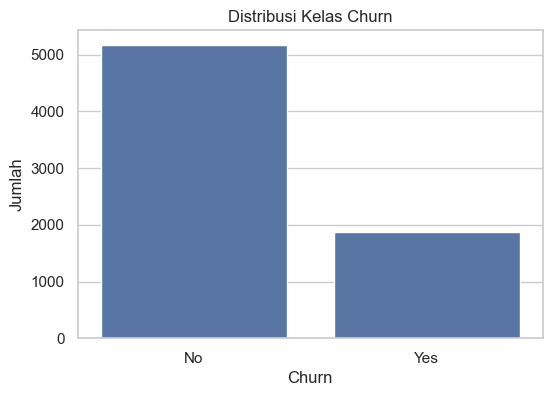

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [6]:
df["Churn_num"] = df["Churn"].map({"No": 0, "Yes": 1})

plt.figure(figsize=(6, 4))
sns.countplot(x="Churn", data=df)
plt.title("Distribusi Kelas Churn")
plt.xlabel("Churn")
plt.ylabel("Jumlah")
plt.show()

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

### 2.3 Hubungan fitur kategorikal dengan churn
Grafik menunjukkan **persentase pelanggan yang churn** pada tiap kategori.

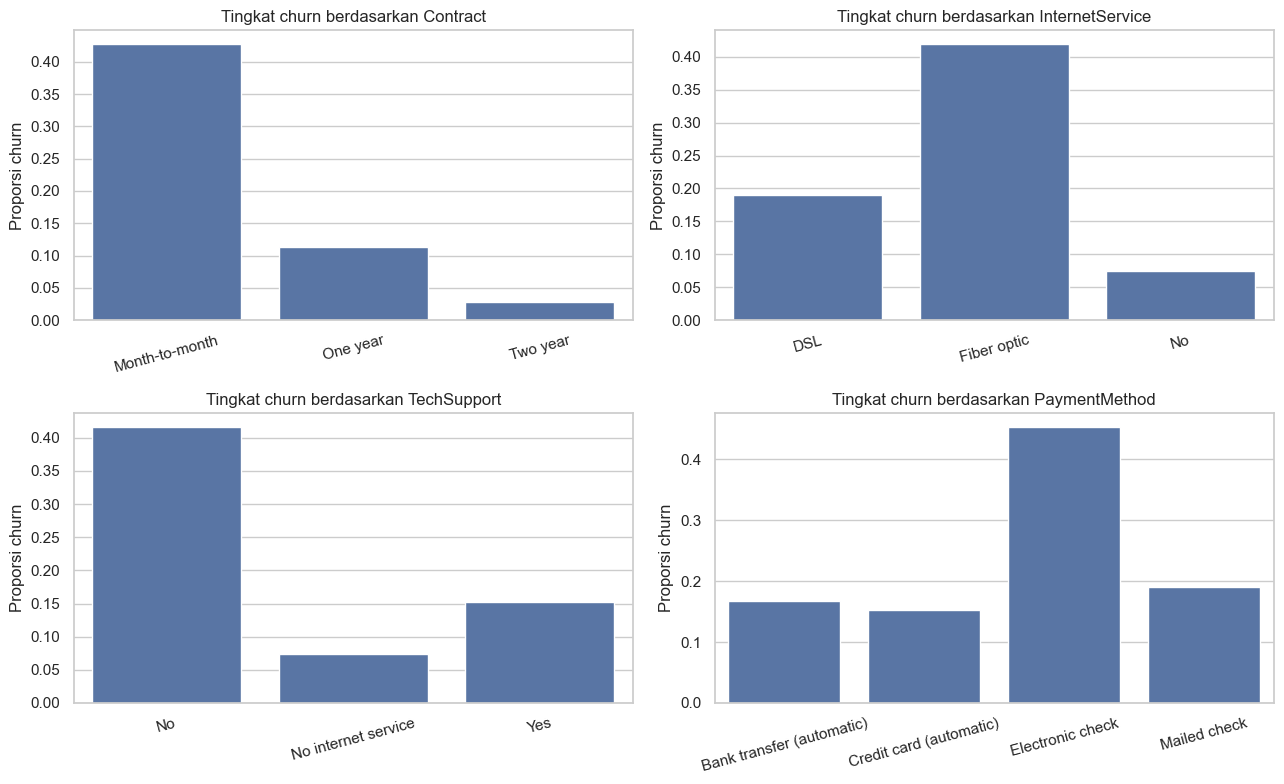

In [7]:
cat_eda = ["Contract", "InternetService", "TechSupport", "PaymentMethod"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), cat_eda):
    rate = df.groupby(col)["Churn_num"].mean().reset_index()
    sns.barplot(data=rate, x=col, y="Churn_num", ax=ax)
    ax.set_title(f"Tingkat churn berdasarkan {col}")
    ax.set_ylabel("Proporsi churn")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### 2.4 Hubungan fitur numerik dengan churn

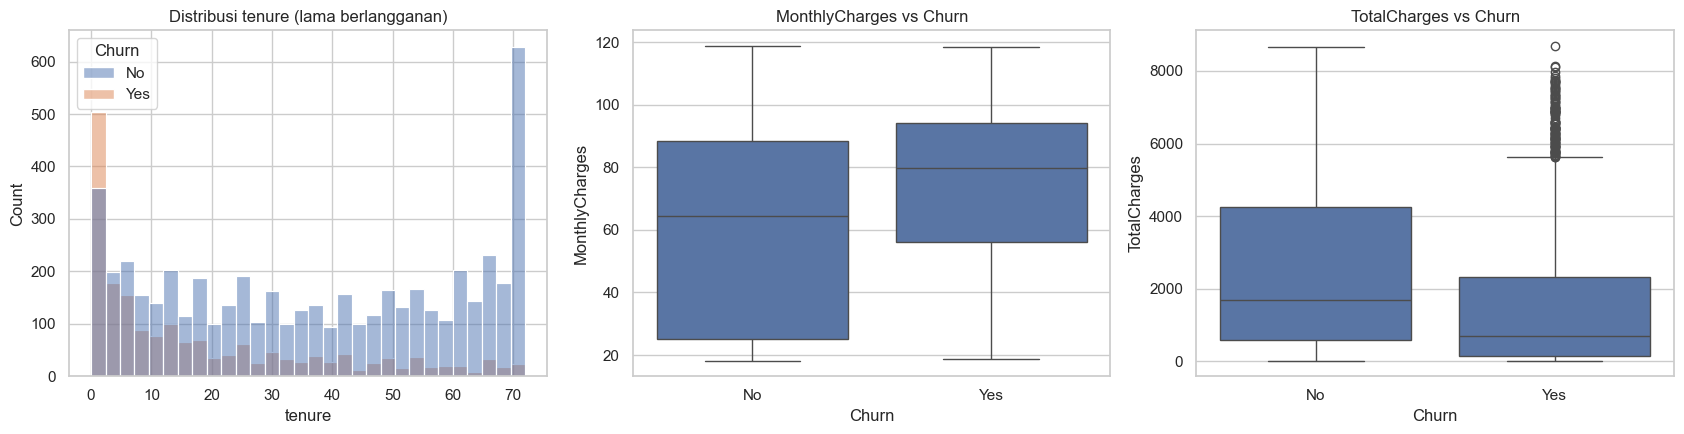

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
axes[0].set_title("Distribusi tenure (lama berlangganan)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("MonthlyCharges vs Churn")
sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[2])
axes[2].set_title("TotalCharges vs Churn")
plt.tight_layout()
plt.show()

### 2.5 Temuan EDA
*(Tulis temuan Anda berdasarkan grafik di atas, misalnya: kontrak mana yang tingkat churn-nya paling tinggi, bagaimana pola tenure pada pelanggan yang churn, apakah jenis internet atau metode pembayaran tertentu berkaitan dengan churn, dan apakah kelas target seimbang.)*

## 3. Pra-pemrosesan

Fitur yang dipakai sama dengan rencana di TP-05, ditambah `PaperlessBilling`:

- **Numerik:** `tenure`, `MonthlyCharges`, `TotalCharges` → imputasi median
- **Kategorikal:** `Contract`, `InternetService`, `OnlineSecurity`, `TechSupport`, `PaymentMethod`, `PaperlessBilling` → One-Hot Encoding

Semua langkah dibungkus dalam satu `Pipeline`, sehingga model yang disimpan bisa langsung menerima data mentah dari formulir web. Data dibagi 80% latih dan 20% uji dengan `stratify=y` agar proporsi churn tetap sama di kedua set.

In [9]:
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = ["Contract", "InternetService", "OnlineSecurity",
            "TechSupport", "PaymentMethod", "PaperlessBilling"]

X = df[NUM_COLS + CAT_COLS]
y = df["Churn_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi churn latih:", round(y_train.mean(), 3), "| uji:", round(y_test.mean(), 3))


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUM_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ],
        sparse_threshold=0,  # selalu keluarkan array padat
    )

Data latih: (5634, 9) | Data uji: (1409, 9)
Proporsi churn latih: 0.265 | uji: 0.265


## 4. Membangun Model

- **Model A (potensi overfit):** `max_depth=None`, pohon tumbuh sampai semua daun murni.
- **Model B (di-pruning):** `max_depth=4` untuk membatasi kompleksitas.

In [10]:
model_a = Pipeline([
    ("prep", make_preprocessor()),
    ("clf", DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE)),
])
model_b = Pipeline([
    ("prep", make_preprocessor()),
    ("clf", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
])

model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)

tree_a = model_a.named_steps["clf"]
print(f"Model A -> kedalaman: {tree_a.get_depth()}, jumlah daun: {tree_a.get_n_leaves()}")
tree_b = model_b.named_steps["clf"]
print(f"Model B -> kedalaman: {tree_b.get_depth()}, jumlah daun: {tree_b.get_n_leaves()}")

Model A -> kedalaman: 30, jumlah daun: 1199
Model B -> kedalaman: 4, jumlah daun: 16


## 5. Evaluasi dan Perbandingan Model

In [11]:
LABELS = ["Bertahan", "Churn"]
results = {}

for name, model in [("Model A (tanpa batas)", model_a), ("Model B (max_depth=4)", model_b)]:
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    proba_test = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "Akurasi latih": accuracy_score(y_train, pred_train),
        "Akurasi uji": accuracy_score(y_test, pred_test),
        "AUC uji": roc_auc_score(y_test, proba_test),
    }

    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Confusion matrix (data uji):")
    print(confusion_matrix(y_test, pred_test))
    print("\nClassification report (data uji):")
    print(classification_report(y_test, pred_test, target_names=LABELS))

comparison = pd.DataFrame(results).T
comparison["Selisih (latih - uji)"] = comparison["Akurasi latih"] - comparison["Akurasi uji"]
comparison.round(4)

Model A (tanpa batas)
Confusion matrix (data uji):
[[855 180]
 [186 188]]

Classification report (data uji):
              precision    recall  f1-score   support

    Bertahan       0.82      0.83      0.82      1035
       Churn       0.51      0.50      0.51       374

    accuracy                           0.74      1409
   macro avg       0.67      0.66      0.67      1409
weighted avg       0.74      0.74      0.74      1409

Model B (max_depth=4)
Confusion matrix (data uji):
[[947  88]
 [205 169]]

Classification report (data uji):
              precision    recall  f1-score   support

    Bertahan       0.82      0.91      0.87      1035
       Churn       0.66      0.45      0.54       374

    accuracy                           0.79      1409
   macro avg       0.74      0.68      0.70      1409
weighted avg       0.78      0.79      0.78      1409



,Akurasi latih,Akurasi uji,AUC uji,Selisih (latih - uji)
Model A (tanpa batas),0.9961,0.7402,0.6692,0.2559
Model B (max_depth=4),0.7966,0.7921,0.8295,0.0045


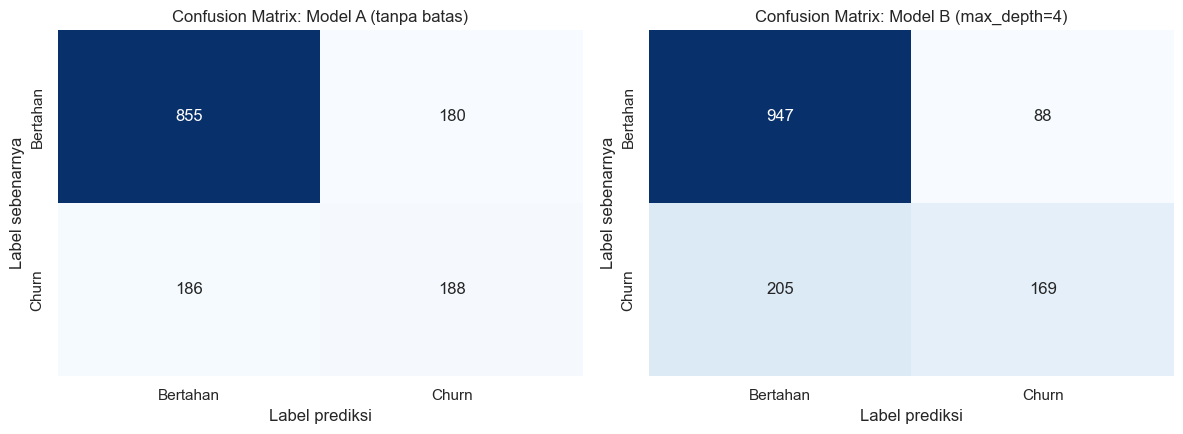

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, model) in zip(axes, [("Model A (tanpa batas)", model_a), ("Model B (max_depth=4)", model_b)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Label prediksi")
    ax.set_ylabel("Label sebenarnya")
plt.tight_layout()
plt.show()

### Bukti overfitting: akurasi latih vs uji terhadap kedalaman pohon

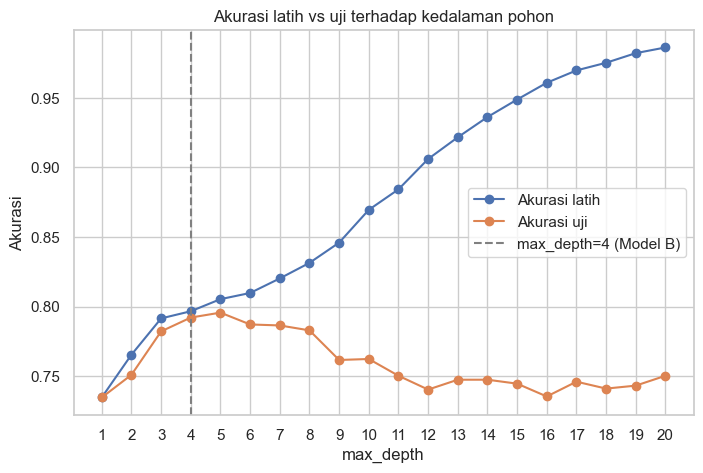

max_depth dengan akurasi uji tertinggi: 5 -> 0.7956


In [13]:
depths = list(range(1, 21))
train_scores, test_scores = [], []
for d in depths:
    m = Pipeline([("prep", make_preprocessor()),
                  ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    m.fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker="o", label="Akurasi latih")
plt.plot(depths, test_scores, marker="o", label="Akurasi uji")
plt.axvline(4, color="gray", linestyle="--", label="max_depth=4 (Model B)")
plt.xlabel("max_depth")
plt.ylabel("Akurasi")
plt.title("Akurasi latih vs uji terhadap kedalaman pohon")
plt.xticks(depths)
plt.legend()
plt.show()

best_d = depths[int(np.argmax(test_scores))]
print("max_depth dengan akurasi uji tertinggi:", best_d, "->", round(max(test_scores), 4))

### Analisis perbandingan Model A dan Model B
*(Tulis analisis Anda di sini, dengan mengacu pada tabel `comparison`, kedua confusion matrix, dan grafik kedalaman di atas. Hal yang perlu dibahas:)*

- Apakah akurasi latih Model A jauh lebih tinggi daripada akurasi ujinya? Berapa selisihnya dibandingkan Model B?
- Berapa kedalaman dan jumlah daun Model A dibandingkan Model B?
- Pada kedalaman berapa akurasi uji mulai turun sementara akurasi latih terus naik?
- Karena kelas churn tidak seimbang, bandingkan juga **recall dan f1-score kelas Churn**, bukan hanya akurasi.
- Model mana yang Anda pilih untuk deployment, dan mengapa?

## 6. Visualisasi dan Interpretasi Model B

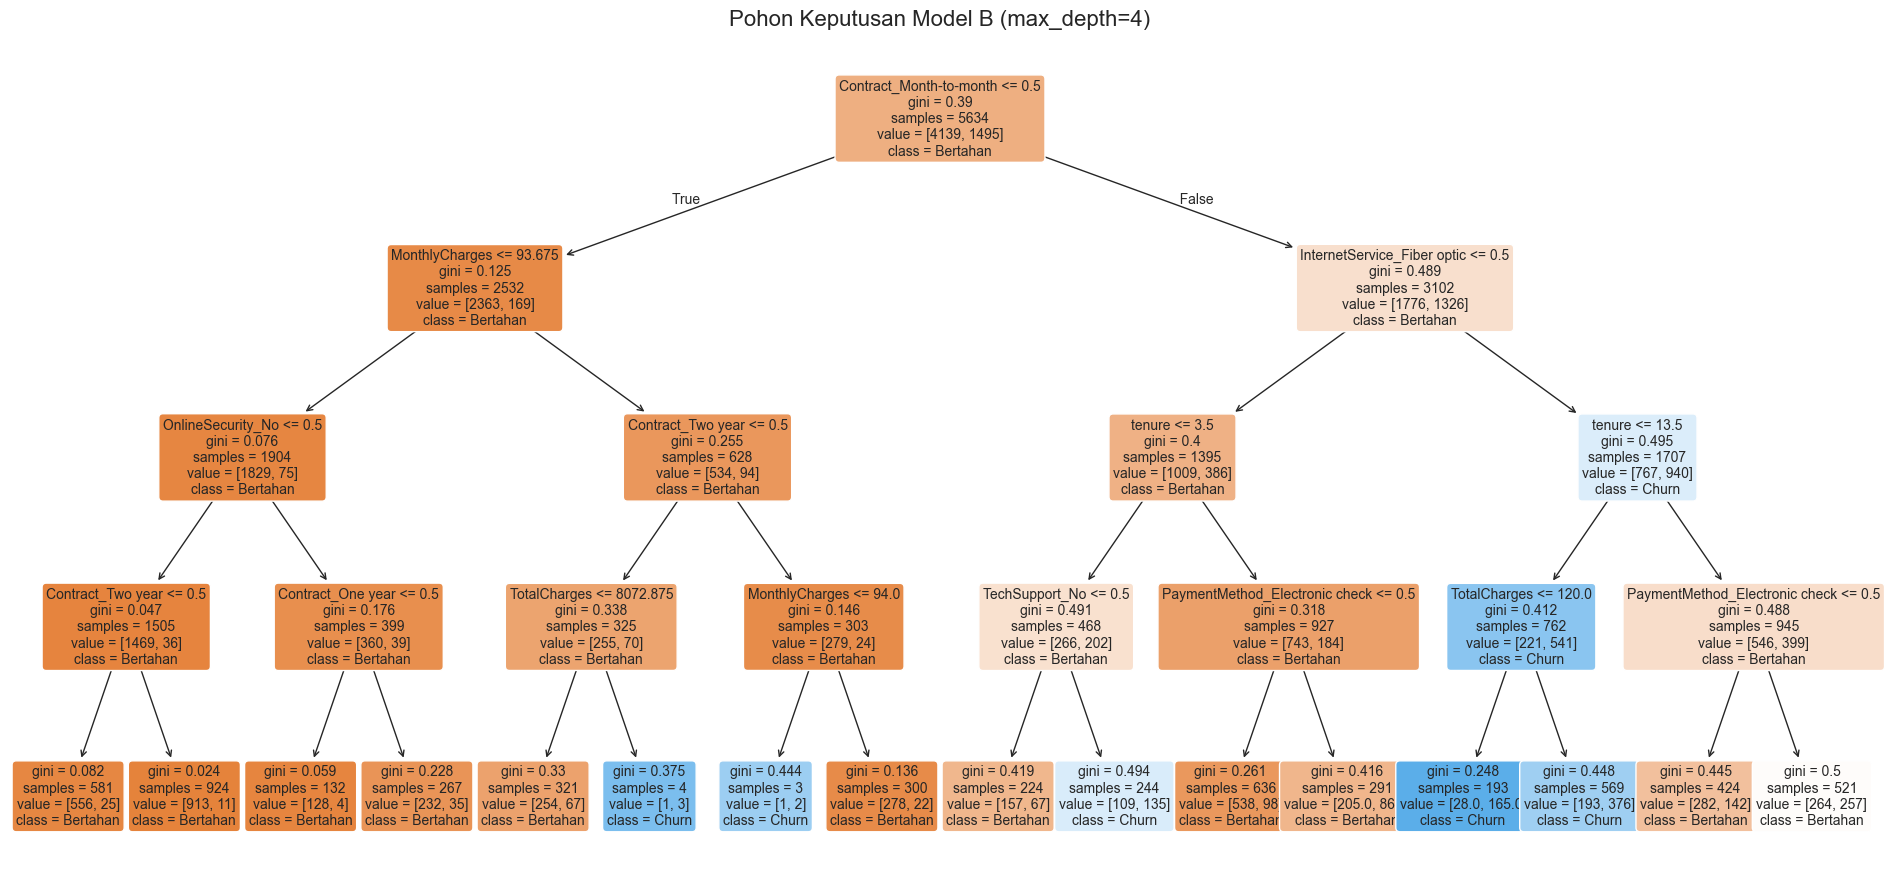

In [14]:
feature_names = model_b.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]  # buang prefix num__ / cat__

plt.figure(figsize=(24, 11))
plot_tree(tree_b,
          feature_names=feature_names,
          class_names=LABELS,
          filled=True, rounded=True, fontsize=10, proportion=False)
plt.title("Pohon Keputusan Model B (max_depth=4)", fontsize=16)
plt.show()

In [15]:
# Versi teks pohon, memudahkan menelusuri jalur akar -> daun
print(export_text(tree_b, feature_names=feature_names, show_weights=True))

|--- Contract_Month-to-month <= 0.50
|   |--- MonthlyCharges <= 93.67
|   |   |--- OnlineSecurity_No <= 0.50
|   |   |   |--- Contract_Two year <= 0.50
|   |   |   |   |--- weights: [556.00, 25.00] class: 0
|   |   |   |--- Contract_Two year >  0.50
|   |   |   |   |--- weights: [913.00, 11.00] class: 0
|   |   |--- OnlineSecurity_No >  0.50
|   |   |   |--- Contract_One year <= 0.50
|   |   |   |   |--- weights: [128.00, 4.00] class: 0
|   |   |   |--- Contract_One year >  0.50
|   |   |   |   |--- weights: [232.00, 35.00] class: 0
|   |--- MonthlyCharges >  93.67
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- TotalCharges <= 8072.88
|   |   |   |   |--- weights: [254.00, 67.00] class: 0
|   |   |   |--- TotalCharges >  8072.88
|   |   |   |   |--- weights: [1.00, 3.00] class: 1
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- MonthlyCharges <= 94.00
|   |   |   |   |--- weights: [1.00, 2.00] class: 1
|   |   |   |--- MonthlyCharges >  94.00
|   |   |   |   |--- weight

### Interpretasi aturan (jalur akar ke daun)
Pilih 2-3 jalur dari plot/teks pohon di atas, lalu terjemahkan menjadi aturan "jika-maka". Catatan membaca pohon: pada fitur hasil One-Hot (misalnya `Contract_Month-to-month <= 0.5`), cabang **True** artinya kontrak *bukan* bulanan, dan cabang **False** artinya kontrak bulanan. Format contoh:

> **Aturan 1:** JIKA kontrak adalah bulanan DAN tenure ≤ *[nilai]* DAN ... MAKA prediksi = **Churn** (*[n]* pelanggan latih di daun ini, *[x]*% churn).

*(Tulis 2-3 aturan Anda dengan angka dari pohon Anda sendiri.)*

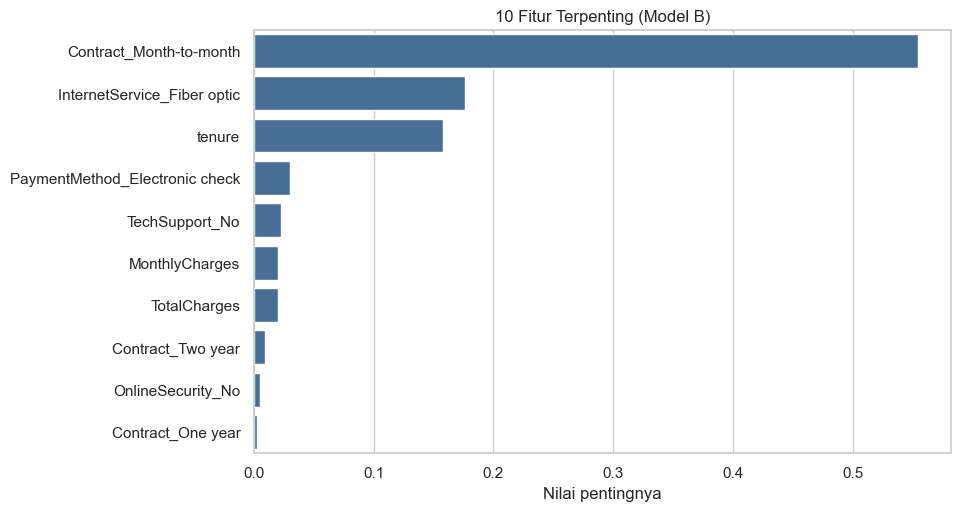

,Fitur,Pentingnya
0,Contract_Month-to-month,0.5539
1,InternetService_Fiber optic,0.1759
2,tenure,0.1583
3,PaymentMethod_Electronic check,0.0301
4,TechSupport_No,0.0230
5,MonthlyCharges,0.0207
6,TotalCharges,0.0201
7,Contract_Two year,0.0099
8,OnlineSecurity_No,0.0052
9,Contract_One year,0.0027


In [16]:
importances = pd.DataFrame({
    "Fitur": feature_names,
    "Pentingnya": tree_b.feature_importances_,
}).sort_values("Pentingnya", ascending=False)

top = importances.head(10)
plt.figure(figsize=(9, 5.5))
sns.barplot(data=top, x="Pentingnya", y="Fitur", color="#3b6ea5")
plt.title("10 Fitur Terpenting (Model B)")
plt.xlabel("Nilai pentingnya")
plt.ylabel("")
plt.show()

importances[importances["Pentingnya"] > 0].round(4).reset_index(drop=True)

### Interpretasi feature importance
*(Jelaskan fitur mana yang paling berpengaruh dan apakah itu masuk akal secara bisnis. Fitur dengan nilai 0 tidak dipakai pohon sama sekali.)*

## 7. Menyimpan Model untuk Aplikasi Flask

Yang disimpan adalah **seluruh pipeline** (pra-pemrosesan + pohon), sehingga aplikasi Flask cukup memberi data mentah dari formulir.

In [17]:
os.makedirs("model", exist_ok=True)
MODEL_PATH = "model/churn_decision_tree.joblib"
joblib.dump(model_b, MODEL_PATH)
print("Model tersimpan:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH)/1024:.1f} KB)")

# Uji muat ulang + prediksi satu pelanggan contoh
loaded = joblib.load(MODEL_PATH)
contoh = pd.DataFrame([{
    "tenure": 3, "MonthlyCharges": 85.0, "TotalCharges": 255.0,
    "Contract": "Month-to-month", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "TechSupport": "No",
    "PaymentMethod": "Electronic check", "PaperlessBilling": "Yes",
}])
print("Probabilitas churn contoh:", round(loaded.predict_proba(contoh)[0, 1], 3))

Model tersimpan: model/churn_decision_tree.joblib (7.3 KB)
Probabilitas churn contoh: 0.661


In [18]:
# Versi library saat model dilatih. Samakan di requirements.txt agar model bisa dimuat saat deployment.
import pandas, numpy
reqs = f"""flask>=3.0
gunicorn>=21.2
pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""
print(reqs)
with open("requirements.txt", "w") as f:
    f.write(reqs)

flask>=3.0
gunicorn>=21.2
pandas==2.1.4
numpy==1.26.4
scikit-learn==1.9.1
joblib==1.6.0

